In [17]:
#carga de nuestro dataset 
import pandas as pd 

#leer
datos = pd.read_csv("../data/dataset.csv")

#pequeña prueba 
datos.head()

,ruta,especie,estado,clase
0,Potato___healthy/b42621c3-f751-46e1-a8d2-83ed8...,Potato,sano,Potato___healthy
1,Potato___healthy/683b04ad-7941-4819-9965-ba32c...,Potato,sano,Potato___healthy
2,Potato___healthy/1ae826e2-5148-47bd-a44c-711ec...,Potato,sano,Potato___healthy
3,Potato___healthy/b4031970-60ea-4739-9fed-6c81b...,Potato,sano,Potato___healthy
4,Potato___healthy/ec6e43d3-512d-4908-99f2-c9e2a...,Potato,sano,Potato___healthy


In [18]:
# tamaño del ds
print("Filas y columnas:", datos.shape)

# nombres de las columnas
print("Columnas:", datos.columns.tolist())

Filas y columnas: (54305, 4)
Columnas: ['ruta', 'especie', 'estado', 'clase']


especie
Tomato                     18160
Orange                      5507
Soybean                     5090
Grape                       4062
Corn_(maize)                3852
Apple                       3171
Peach                       2657
Pepper,_bell                2475
Potato                      2152
Cherry_(including_sour)     1906
Squash                      1835
Strawberry                  1565
Blueberry                   1502
Raspberry                    371
Name: count, dtype: int64


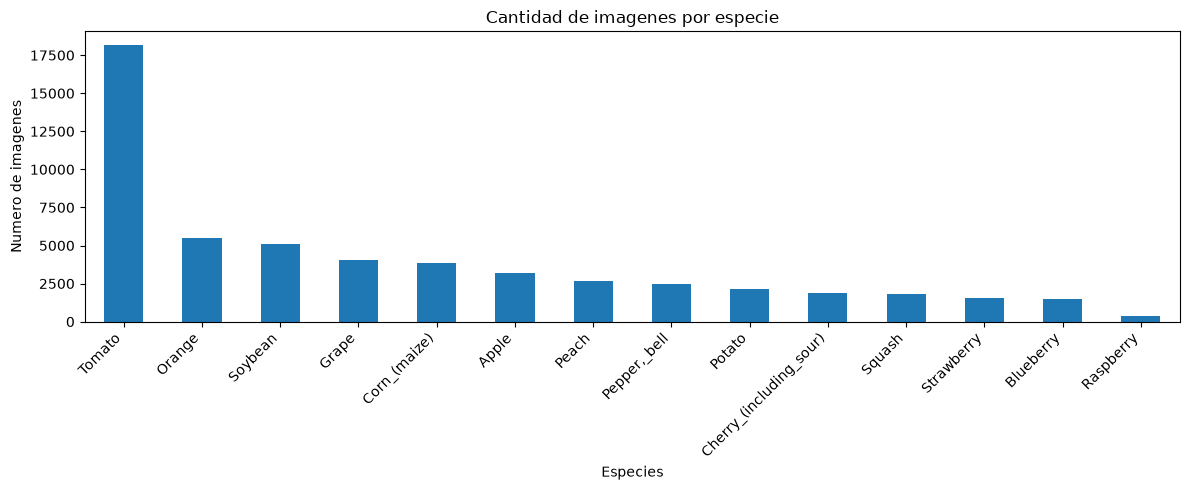

In [19]:
# Contar cuantas imagenes tiene cada especie
conteo_especies = datos["especie"].value_counts()

print(conteo_especies)

import matplotlib.pyplot as plt

# Crear la grafica
conteo_especies.plot(kind="bar", figsize=(12, 5))

# Agregar titulo y nombres de los ejes
plt.title("Cantidad de imagenes por especie")
plt.xlabel("Especies")
plt.ylabel("Numero de imagenes")

# Acomodar los nombres
plt.xticks(rotation=45, ha="right")

# Mostrar la grafica
plt.tight_layout()
plt.show()

In [20]:
# Contar plantas sanas y enfermas
conteo_estados = datos["estado"].value_counts()

print(conteo_estados)

estado
enfermo    39221
sano       15084
Name: count, dtype: int64


estado
enfermo    72.223552
sano       27.776448
Name: proportion, dtype: float64


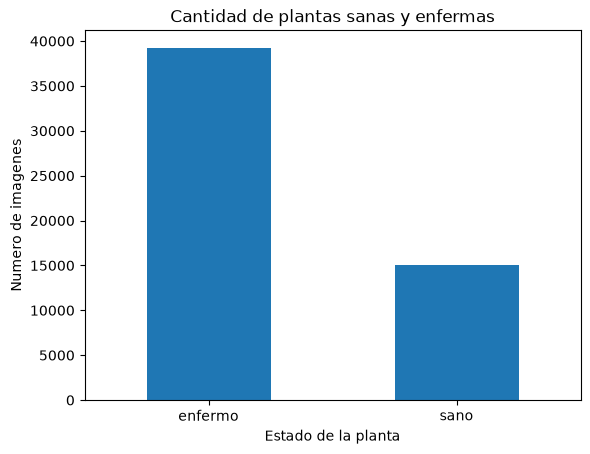

In [21]:
# Calcular porcentajes de plantas sanas y enfermas
porcentajes = datos["estado"].value_counts(normalize=True) * 100

print(porcentajes)

# Grafica de plantas sanas y enfermas
conteo_estados.plot(kind="bar")

plt.title("Cantidad de plantas sanas y enfermas")
plt.xlabel("Estado de la planta")
plt.ylabel("Numero de imagenes")

plt.xticks(rotation=0)
plt.show()

clase
Orange___Haunglongbing_(Citrus_greening)              5507
Tomato___Tomato_Yellow_Leaf_Curl_Virus                5357
Soybean___healthy                                     5090
Peach___Bacterial_spot                                2297
Tomato___Bacterial_spot                               2127
Tomato___Late_blight                                  1909
Squash___Powdery_mildew                               1835
Tomato___Septoria_leaf_spot                           1771
Tomato___Spider_mites Two-spotted_spider_mite         1676
Apple___healthy                                       1645
Tomato___healthy                                      1591
Blueberry___healthy                                   1502
Pepper,_bell___healthy                                1478
Tomato___Target_Spot                                  1404
Grape___Esca_(Black_Measles)                          1383
Corn_(maize)___Common_rust_                           1192
Grape___Black_rot                                 

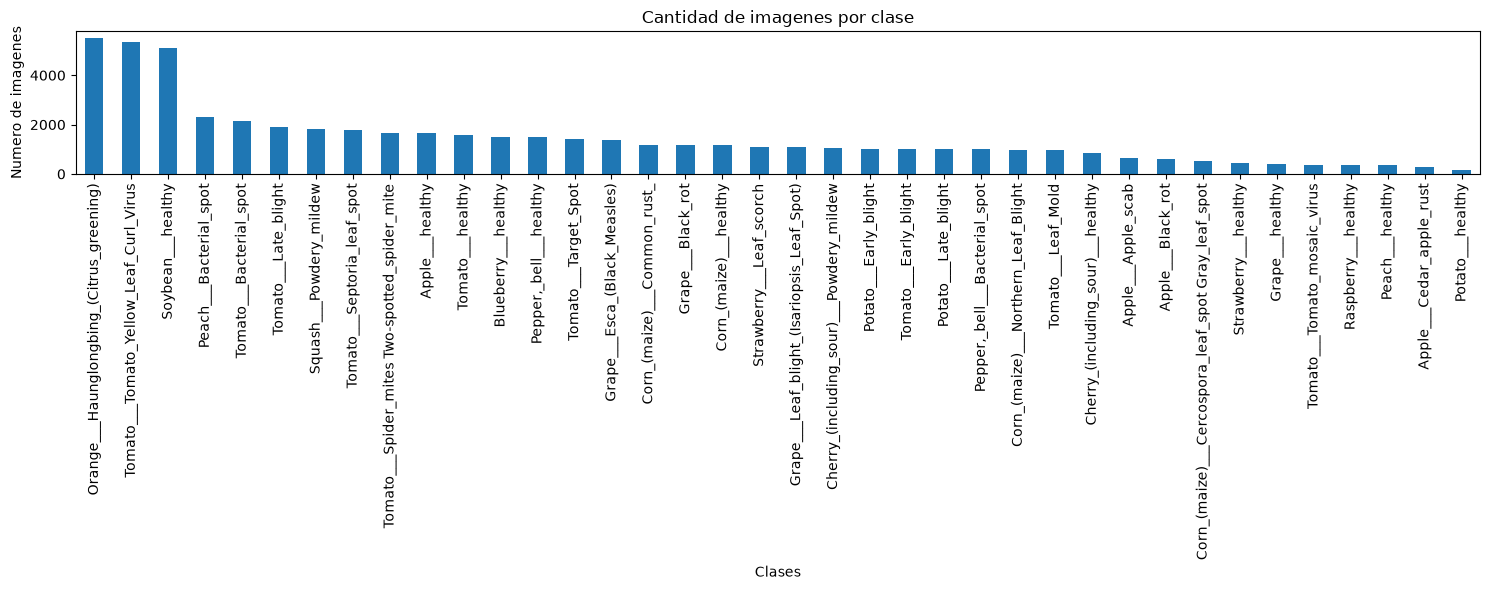

In [22]:
# Contar imagenes por clase
conteo_clases = datos["clase"].value_counts()

print(conteo_clases)

# Comprobar cuantas clases tenemos
print("Total de clases:", len(conteo_clases))

# Grafica de imagenes por clase
conteo_clases.plot(kind="bar", figsize=(15, 6))

plt.title("Cantidad de imagenes por clase")
plt.xlabel("Clases")
plt.ylabel("Numero de imagenes")

plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [23]:
# Mostrar las 5 clases con mas imagenes
print("Clases con mas imagenes:")
print(conteo_clases.head(5))

# Mostrar las 5 clases con menos imagenes
print("\nClases con menos imagenes:")
print(conteo_clases.tail(5))

Clases con mas imagenes:
clase
Orange___Haunglongbing_(Citrus_greening)    5507
Tomato___Tomato_Yellow_Leaf_Curl_Virus      5357
Soybean___healthy                           5090
Peach___Bacterial_spot                      2297
Tomato___Bacterial_spot                     2127
Name: count, dtype: int64

Clases con menos imagenes:
clase
Tomato___Tomato_mosaic_virus    373
Raspberry___healthy             371
Peach___healthy                 360
Apple___Cedar_apple_rust        275
Potato___healthy                152
Name: count, dtype: int64


In [24]:
# Revisar valores faltantes
print(datos.isnull().sum())

# Revisar registros duplicados
print("\nFilas duplicadas:", datos.duplicated().sum())

ruta       0
especie    0
estado     0
clase      0
dtype: int64

Filas duplicadas: 0


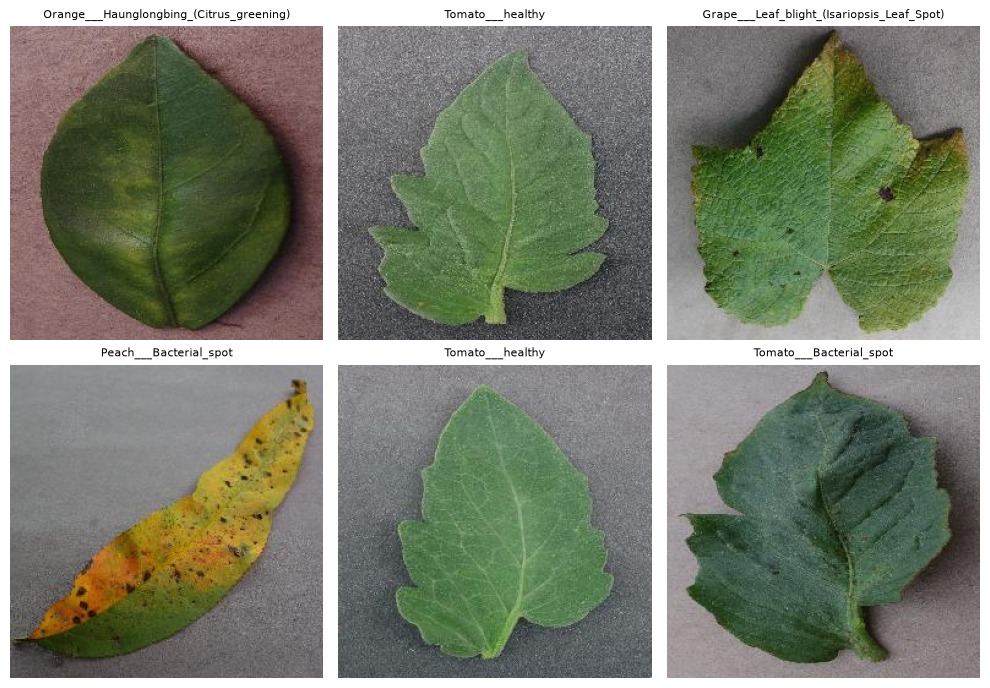

In [25]:
# Mostrar 6 imagenes del dataset
from PIL import Image
import os

figura, ejes = plt.subplots(2, 3, figsize=(10, 7))

# Elegir 6 imagenes aleatorias
muestras = datos.sample(6, random_state=42)

for eje, (_, fila) in zip(ejes.flat, muestras.iterrows()):
    ruta = os.path.join("../data/plantvillage", fila["ruta"])

    imagen = Image.open(ruta)
    eje.imshow(imagen)
    eje.set_title(fila["clase"], fontsize=8)
    eje.axis("off")

plt.tight_layout()
plt.show()

In [26]:
# Revisar dimensiones y formato de una imagen
print("Dimensiones:", imagen.size)
print("Modo de color:", imagen.mode)

Dimensiones: (256, 256)
Modo de color: RGB


In [27]:
# Verificar imagenes dañadas
imagenes_danadas = []

for ruta in datos["ruta"]:
    ruta_completa = os.path.join("../data/plantvillage", ruta)

    try:
        with Image.open(ruta_completa) as imagen:
            imagen.verify()
    except Exception:
        imagenes_danadas.append(ruta)

print("Imagenes revisadas:", len(datos))
print("Imagenes dañadas:", len(imagenes_danadas))

Imagenes revisadas: 54305
Imagenes dañadas: 0


In [28]:
# Crear carpeta para guardar las graficas
import os

os.makedirs("../resultados/figuras", exist_ok=True)

# Guardar grafica de especies
conteo_especies.plot(kind="bar", figsize=(12, 5))
plt.title("Cantidad de imagenes por especie")
plt.tight_layout()
plt.savefig("../resultados/figuras/especies.png")
plt.close()

# Guardar grafica de estados
conteo_estados.plot(kind="bar")
plt.title("Plantas sanas y enfermas")
plt.tight_layout()
plt.savefig("../resultados/figuras/estados.png")
plt.close()

# Guardar grafica de clases
conteo_clases.plot(kind="bar", figsize=(15, 6))
plt.title("Cantidad de imagenes por clase")
plt.tight_layout()
plt.savefig("../resultados/figuras/clases.png")
plt.close()

print("Graficas guardadas correctamente")

Graficas guardadas correctamente
